In [2]:
import pandas as pd
import numpy as np
import random
import seaborn as sns
import matplotlib.pyplot as plt

random_df = pd.read_csv("/My_project/random_sampling_results.csv")


def analyze_poisson_behavior(df):
    target_masses = sorted(df["target_mass"].unique())

    means = []
    variances = []
    fano_factors = []

    print(f"{'M_cl':>10} | {'Mean N':>10} | {'Var N':>10} | {'Fano Factor':>12}")
    print("-" * 50)

    for m in target_masses:
        n_stars = df[df["target_mass"] == m]["n_stars"]

        mu = n_stars.mean()
        var = n_stars.var()
        fano = var / mu if mu > 0 else 0

        means.append(mu)
        variances.append(var)
        fano_factors.append(fano)

        print(f"{m:10.0f} | {mu:10.2f} | {var:10.2f} | {fano:12.4f}")

    plt.figure(figsize=(8,6))
    plt.plot(target_masses, fano_factors, 'o-', color='navy', linewidth=2, markersize=8)
    plt.axhline(1.0, color='darkred', linestyle='--', label='Pure Poisson (F=1)')

    plt.xscale('log')
    plt.xlabel(r"$M_{cl} \ [M_\odot]$", fontsize=19)
    plt.ylabel(r"Fano factor", fontsize=19)
    plt.legend(fontsize=16)
    plt.tick_params(labelsize=15)

    plt.show()

      M_cl |     Mean N |      Var N |  Fano Factor
--------------------------------------------------
        50 |     101.56 |     516.65 |       5.0872
       100 |     189.93 |    1461.38 |       7.6944
       300 |     532.16 |    6994.44 |      13.1434
      1000 |    1722.91 |   26085.76 |      15.1406
      3000 |    5139.10 |   81018.92 |      15.7652
     10000 |   17091.16 |  277536.59 |      16.2386


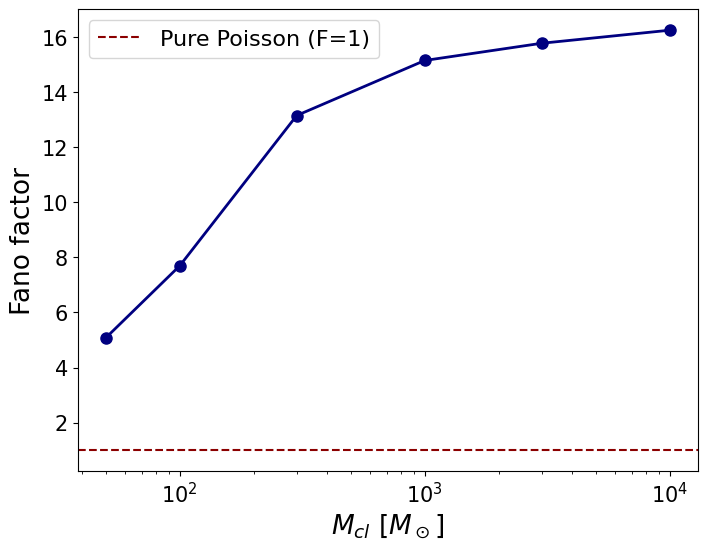

In [34]:
analyze_poisson_behavior(random_df)

target_mass      50        100       300       1000      3000      10000
bin                                                                     
bin_10_count       NaN  0.995500  0.953031  0.914968  0.930050  0.923071
bin_1_count   3.045880  3.912558  5.935362  6.673832  6.982586  7.091340
bin_2_count   2.470099  3.249033  4.853642  5.464039  5.585349  5.830711
bin_3_count   1.825947  2.419475  3.592779  3.990196  4.084131  4.214334
bin_4_count   1.149628  1.421160  1.877659  2.087768  2.125907  2.163859
bin_5_count   0.917604  1.027177  1.208146  1.274795  1.297226  1.290839
bin_6_count   0.867672  0.896942  0.979254  1.009670  1.011413  1.029143
bin_7_count   0.881087  0.863856  0.905398  0.906223  0.906461  0.912294
bin_8_count   0.915256  0.893805  0.907476  0.903569  0.911283  0.915746
bin_9_count   0.991999  0.939219  0.916666  0.912907  0.905728  0.886000


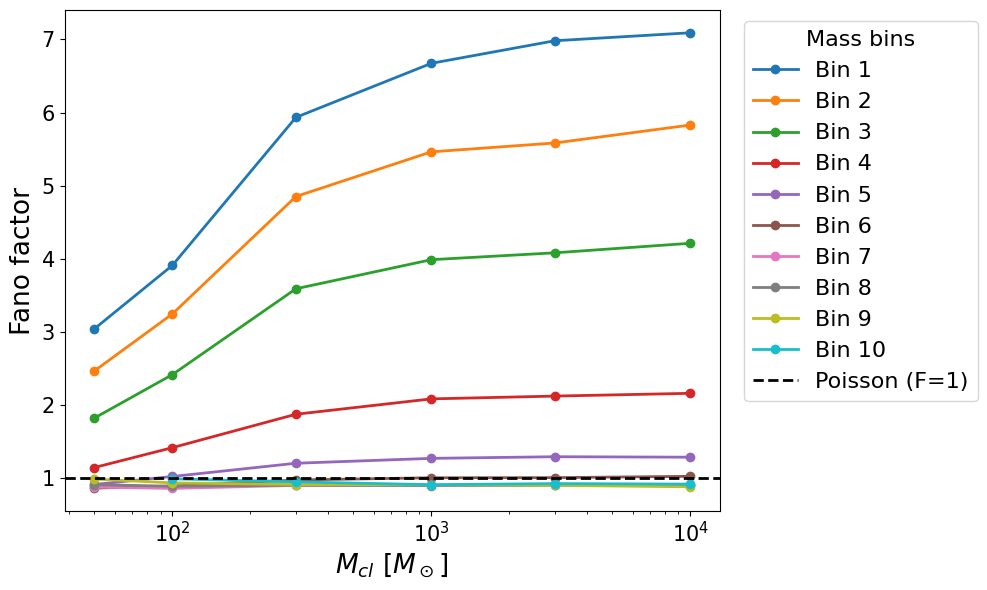

In [35]:
bin_cols = [col for col in random_df.columns if "bin_" in col and "_count" in col]
bin_data = random_df[bin_cols]
results = []

for mass, group in random_df.groupby("target_mass"):

    for col in bin_cols:
        data = group[col]

        mean = data.mean()
        var = data.var(ddof=1)
        fano = var / mean if mean > 0 else np.nan

        results.append({
            "target_mass": mass,
            "bin": col,
            "mean": mean,
            "var": var,
            "fano": fano
        })

stats_df = pd.DataFrame(results)

pivot_fano = stats_df.pivot(index="bin", columns="target_mass", values="fano")
print(pivot_fano)

plt.figure(figsize=(10,6))

for b in sorted(stats_df["bin"].unique(), key=lambda x: int(x.split('_')[1])):
    sub = stats_df[stats_df["bin"] == b]
    clean_label = b.replace("_count", "").replace("bin_", "Bin ")
    plt.plot(sub["target_mass"], sub["fano"], marker="o", label=clean_label, linewidth=2)

plt.xscale("log")

plt.axhline(1.0, linestyle="--", color="black", linewidth=2, label="Poisson (F=1)")
plt.xlabel(r"$M_{cl} \ [M_\odot]$", fontsize=19)
plt.ylabel(r"Fano factor", fontsize=19)
plt.tick_params(axis='both', which='major', labelsize=15)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Mass bins", fontsize=16, title_fontsize=16)

plt.tight_layout()
plt.show()

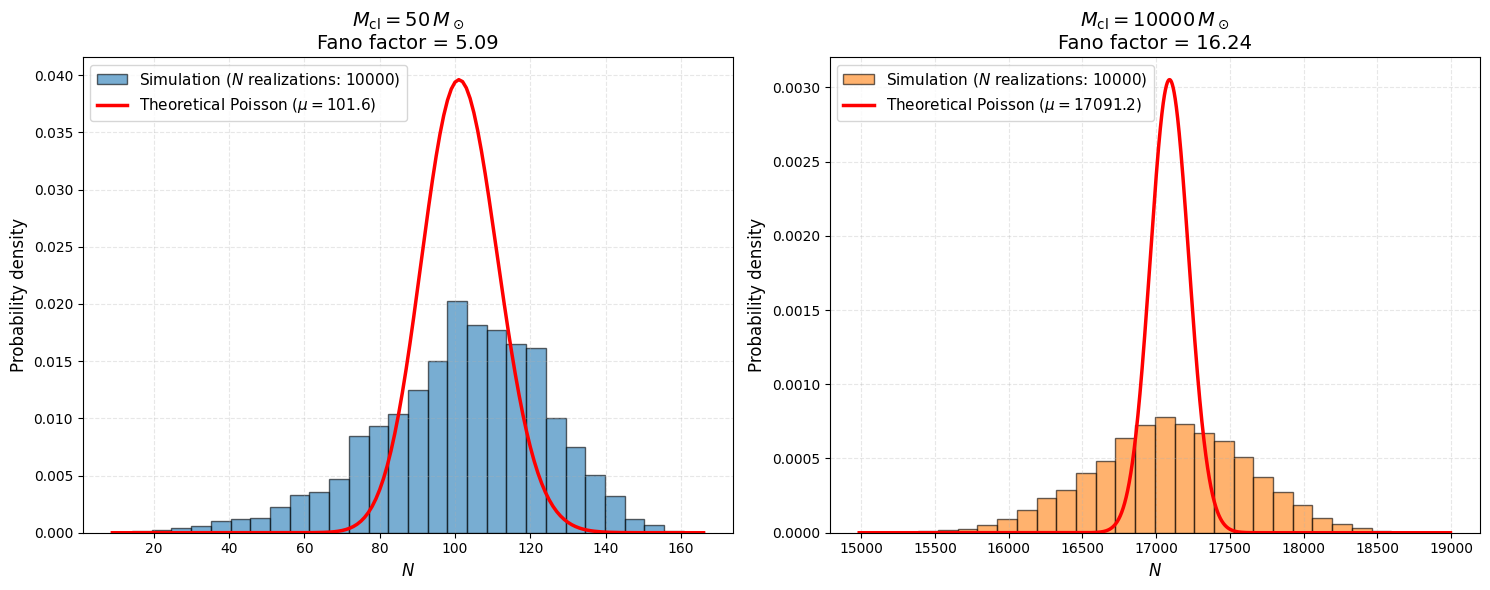

In [6]:
from scipy.stats import poisson

def plot_poisson_comparison(df, masses_to_show=[50, 10000]):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    colors = ['#1f77b4', '#ff7f0e']

    for i, M_test in enumerate(masses_to_show):
        ax = axes[i]

        data_n = df[df["target_mass"] == M_test]["n_stars"]

        mu = data_n.mean()
        var = data_n.var()
        fano = var / mu if mu > 0 else 0

        ax.hist(data_n, bins=30, density=True, alpha=0.6, color=colors[i],
                edgecolor='black', label=f"Simulation ($N$ realizations: {len(data_n)})")

        x = np.arange(data_n.min(), data_n.max() + 1)
        ax.plot(x, poisson.pmf(x, mu), 'r-', lw=2.5, label=f"Theoretical Poisson ($\\mu={mu:.1f}$)")

        ax.set_title(fr"$M_{{\rm cl}} = {M_test}\,M_\odot$" "\n" fr"Fano factor = {fano:.2f}", fontsize=14)
        ax.set_xlabel("$N$", fontsize=12)
        ax.set_ylabel("Probability density", fontsize=12)
        ax.legend(fontsize=11)
        ax.grid(True, alpha=0.3, ls='--')

    plt.tight_layout()
    plt.show()


plot_poisson_comparison(random_df, masses_to_show=[50, 10000])

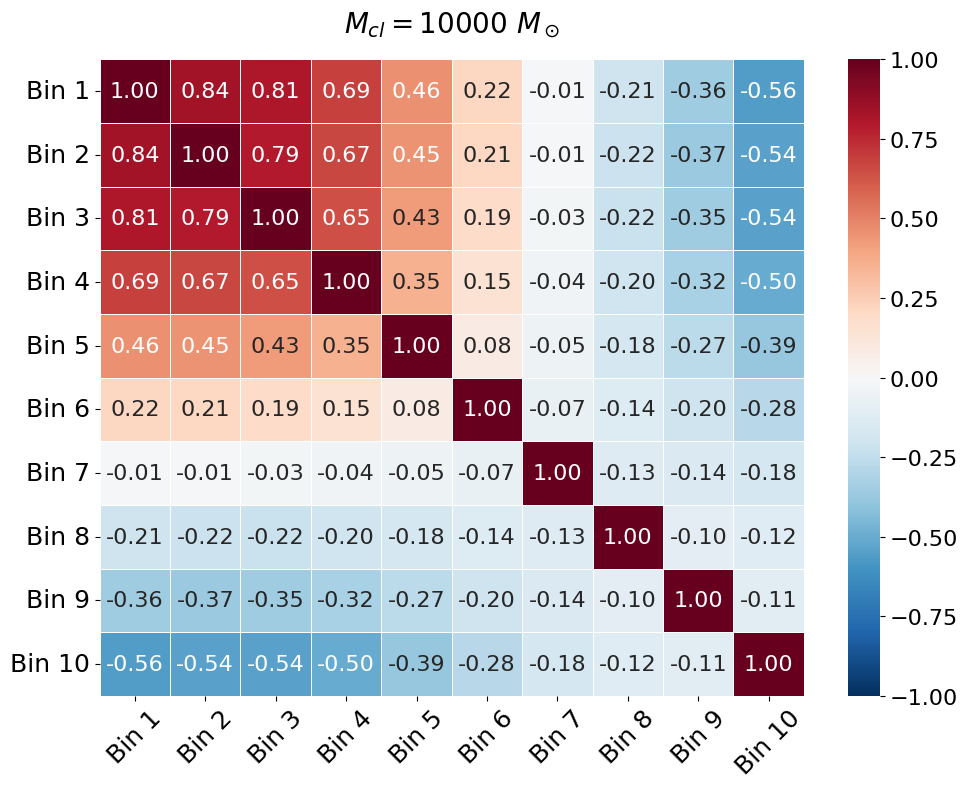

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt

mass_to_plot = 10000
subset = random_df[random_df["target_mass"] == mass_to_plot]

bin_cols = [col for col in random_df.columns if "bin_" in col and "_count" in col]
corr_matrix = subset[bin_cols].corr()

new_labels = [col.replace("_count", "").replace("bin_", "Bin ").replace("_", " ") for col in bin_cols]

corr_matrix.columns = new_labels
corr_matrix.index = new_labels

plt.figure(figsize=(10, 8))
ax = sns.heatmap(corr_matrix,
            annot=True,
            fmt=".2f",
            cmap="RdBu_r",
            center=0,
            vmin=-1, vmax=1,
            linewidths=0.5,
            annot_kws={"size": 16})

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=16)

plt.title(fr"$M_{{cl}} = {mass_to_plot}\ M_\odot$", fontsize=20, pad=20)
plt.xticks(rotation=45, fontsize = 18)
plt.yticks(rotation=0, fontsize = 18)
plt.tight_layout()

plt.show()

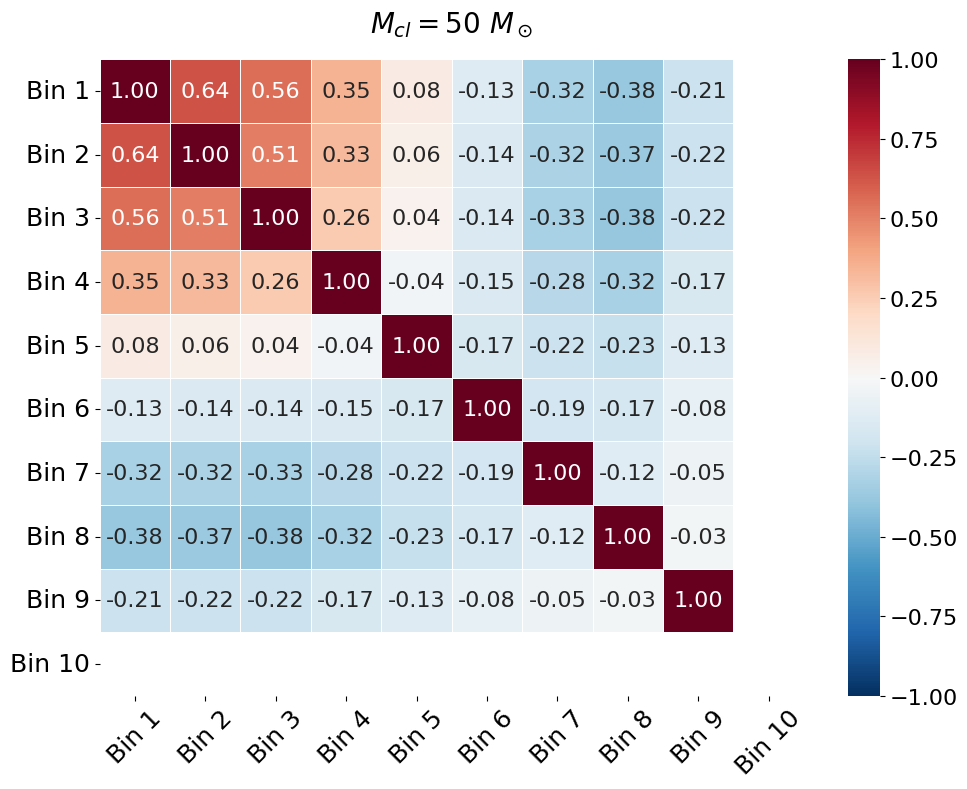

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt

mass_to_plot = 50
subset = random_df[random_df["target_mass"] == mass_to_plot]

bin_cols = [col for col in random_df.columns if "bin_" in col and "_count" in col]
corr_matrix = subset[bin_cols].corr()

new_labels = [col.replace("_count", "").replace("bin_", "Bin ").replace("_", " ") for col in bin_cols]

corr_matrix.columns = new_labels
corr_matrix.index = new_labels

plt.figure(figsize=(10, 8))
ax = sns.heatmap(corr_matrix,
                 annot=True,
                 fmt=".2f",
                 cmap="RdBu_r",
                 center=0,
                 vmin=-1, vmax=1,
                 linewidths=0.5,
                 annot_kws={"size": 16})

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=16)

plt.title(fr"$M_{{cl}} = {mass_to_plot}\ M_\odot$", fontsize=20, pad=20)
plt.xticks(rotation=45, fontsize=18)
plt.yticks(rotation=0, fontsize=18)
plt.tight_layout()

plt.show()

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
from sklearn.model_selection import GroupShuffleSplit, cross_validate
from sklearn.dummy import DummyClassifier

file_name = '../data/ML_dataset_balanced.csv'
df = pd.read_csv(file_name)

features_final = [
    "luminosity_ratio",
    "m1_over_m2",
    "top3_mass_fraction",
    "top5_mass_fraction",
    "q75_over_q25",

    "mass_fraction_above_0p5",
    "mass_fraction_above_1",
    "mass_fraction_above_2",
    "mass_fraction_above_4",
    "mass_fraction_above_8",

    "bin_1_fraction",
    "bin_2_fraction",
    "bin_3_fraction",
    "bin_4_fraction",
    "bin_5_fraction",
    "bin_6_fraction",
    "bin_7_fraction",
    "bin_8_fraction",
    "bin_9_fraction",
    "bin_10_fraction",
]

X = df[features_final]
y = df["label"]

# Definice modelů
model_dummy = DummyClassifier(strategy='stratified', random_state=42)  # Baseline model
model_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
model_rf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=4, class_weight='balanced')
model_svm = make_pipeline(StandardScaler(), SVC(probability=True, random_state=42, class_weight='balanced'))
model_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

models = {
    "Dummy (baseline)": model_dummy,
    "Logistic regresion": model_lr,
    "Random Forest (h=4)": model_rf,
    "SVM": model_svm,
    "KNN": model_knn
}


# Function for listing the importance of features
def print_feature_importances(model_name, model, feature_names):
    print(f"   [!] Top 5 features: {model_name}")
    if isinstance(model, RandomForestClassifier):
        importances = model.feature_importances_
        df_imp = pd.DataFrame({'Feature': feature_names, 'Weight': importances})
        print(df_imp.sort_values(by='Weight', ascending=False).head(5).to_string(index=False))
    elif hasattr(model, 'named_steps') and 'logisticregression' in model.named_steps:
        coefs = model.named_steps['logisticregression'].coef_[0]
        df_coef = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefs, 'Abs_Koef': np.abs(coefs)})
        print(df_coef.sort_values(by='Abs_Koef', ascending=False)[['Feature', 'Coefficient']].head(5).to_string(
            index=False))
    print("")


# EXPERIMENT 1 & 2: Group cross validation
print("=== EXPERIMENT 1 & 2: GROUP CROSS VALIDATION (50 iterations) ===")

groups = df['target_mass']

cv_group = GroupShuffleSplit(n_splits=50, test_size=0.2, random_state=42)

scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'}

for name, model in models.items():
    scores = cross_validate(model, X, y, groups=groups, cv=cv_group, scoring=scoring, n_jobs=-1)

    mean_roc = scores['test_roc_auc'].mean()
    std_roc = scores['test_roc_auc'].std()
    mean_pr = scores['test_pr_auc'].mean()
    std_pr = scores['test_pr_auc'].std()

    print(f"{name:<20}: ROC AUC = {mean_roc:.4f} ± {std_roc:.4f} | PR AUC = {mean_pr:.4f} ± {std_pr:.4f}")

print("\n=== TOP 5 FEATURES: FULL FEATURE SET ===")

for name in ["Logistic regresion", "Random Forest (h=4)"]:
    model = models[name]
    model.fit(X, y)
    print_feature_importances(name, model, features_final)

# EXPERIMENT 3: EXTRAPOLATION
print("\n=== EXPERIMENT 3: EXTRAPOLATIONm(100 iterations) ===")
prah = 1000
df_male = df[df['target_mass'] <= prah]
df_velke = df[df['target_mass'] > prah]

X_train_m, y_train_m = df_male[features_final], df_male['label']
X_test_v, y_test_v = df_velke[features_final], df_velke['label']

X_train_v, y_train_v = df_velke[features_final], df_velke['label']
X_test_m, y_test_m = df_male[features_final], df_male['label']


def run_extrapolation_experiment(title, X_train, y_train, X_test, y_test):
    print(f"\n{title}")
    print("-" * len(title))

    for name, model in models.items():
        model.fit(X_train, y_train)

        if name in ["Logistic regresion", "Random Forest (h=4)"]:
            print_feature_importances(name, model, features_final)

        y_pred_proba = model.predict_proba(X_test)[:, 1]
        roc_scores, pr_scores = [], []
        y_test_array = np.array(y_test)

        for i in range(100):
            indices = resample(range(len(y_test_array)), random_state=i)
            if len(np.unique(y_test_array[indices])) < 2:
                continue
            roc_scores.append(roc_auc_score(y_test_array[indices], y_pred_proba[indices]))
            pr_scores.append(average_precision_score(y_test_array[indices], y_pred_proba[indices]))

        print(
            f"   => {name:<20}: ROC AUC = {np.mean(roc_scores):.4f} ± {np.std(roc_scores):.4f} | PR AUC = {np.mean(pr_scores):.4f} ± {np.std(pr_scores):.4f}\n")


run_extrapolation_experiment(
    "--- Training on low-mass clusters (<= 1000), testing on high-mass clusters (> 1000) ---", X_train_m, y_train_m, X_test_v, y_test_v)

run_extrapolation_experiment(
    "--- Training on high-mass clusters (> 1000), testing on low-mass clusters (<= 1000) ---", X_train_v, y_train_v, X_test_m, y_test_m)

=== EXPERIMENT 1 & 2: GROUP CROSS VALIDATION (50 iterations) ===
Dummy (baseline)    : ROC AUC = 0.4982 ± 0.0000 | PR AUC = 0.4991 ± 0.0000
Logistic regresion  : ROC AUC = 0.8386 ± 0.0062 | PR AUC = 0.7365 ± 0.0099
Random Forest (h=4) : ROC AUC = 0.9996 ± 0.0001 | PR AUC = 0.9996 ± 0.0002
SVM                 : ROC AUC = 0.9996 ± 0.0002 | PR AUC = 0.9994 ± 0.0003
KNN                 : ROC AUC = 0.9959 ± 0.0012 | PR AUC = 0.9919 ± 0.0023

=== TOP 5 FEATURES: FULL FEATURE SET ===
   [!] Top 5 features: Logistic regresion
           Feature  Coefficient
        m1_over_m2    -7.594236
top3_mass_fraction    -4.932210
  luminosity_ratio     2.023623
   bin_10_fraction    -2.015864
top5_mass_fraction     1.976164

   [!] Top 5 features: Random Forest (h=4)
                Feature   Weight
             m1_over_m2 0.214521
         bin_1_fraction 0.107607
         bin_3_fraction 0.096361
mass_fraction_above_0p5 0.086719
  mass_fraction_above_2 0.083864


=== EXPERIMENT 3: EXTRAPOLATIONm(100 ite

In [12]:
# unbalanced dataset
file_name = 'ML_dataset_unbalanced.csv'
df = pd.read_csv(file_name)

features_final = [
    "luminosity_ratio",
    "m1_over_m2",
    "top3_mass_fraction",
    "top5_mass_fraction",
    "q75_over_q25",

    "mass_fraction_above_0p5",
    "mass_fraction_above_1",
    "mass_fraction_above_2",
    "mass_fraction_above_4",
    "mass_fraction_above_8",

    "bin_1_fraction",
    "bin_2_fraction",
    "bin_3_fraction",
    "bin_4_fraction",
    "bin_5_fraction",
    "bin_6_fraction",
    "bin_7_fraction",
    "bin_8_fraction",
    "bin_9_fraction",
    "bin_10_fraction",
]

X = df[features_final]
y = df["label"]

# Models
model_dummy = DummyClassifier(strategy='stratified', random_state=42)  # Baseline model
model_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
model_rf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=4, class_weight='balanced')
model_svm = make_pipeline(StandardScaler(), SVC(probability=True, random_state=42, class_weight='balanced'))
model_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

models = {
    "Dummy (baseline)": model_dummy,
    "Logistic regresion": model_lr,
    "Random Forest (h=4)": model_rf,
    "SVM": model_svm,
    "KNN": model_knn
}


# Function for listing the importance of features
def print_feature_importances(model_name, model, feature_names):
    print(f"   [!] Top 5 features: {model_name}")
    if isinstance(model, RandomForestClassifier):
        importances = model.feature_importances_
        df_imp = pd.DataFrame({'Feature': feature_names, 'Weight': importances})
        print(df_imp.sort_values(by='Weight', ascending=False).head(5).to_string(index=False))
    elif hasattr(model, 'named_steps') and 'logisticregression' in model.named_steps:
        coefs = model.named_steps['logisticregression'].coef_[0]
        df_coef = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefs, 'Abs_Koef': np.abs(coefs)})
        print(df_coef.sort_values(by='Abs_Koef', ascending=False)[['Feature', 'Coefficient']].head(5).to_string(
            index=False))
    print("")


# EXPERIMENT 1 & 2: Group cross validation
print("=== EXPERIMENT 1 & 2: GROUP CROSS VALIDATION (50 iterations) ===")

groups = df['target_mass']

cv_group = GroupShuffleSplit(n_splits=50, test_size=0.2, random_state=42)

scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'}

for name, model in models.items():
    scores = cross_validate(model, X, y, groups=groups, cv=cv_group, scoring=scoring, n_jobs=-1)

    mean_roc = scores['test_roc_auc'].mean()
    std_roc = scores['test_roc_auc'].std()
    mean_pr = scores['test_pr_auc'].mean()
    std_pr = scores['test_pr_auc'].std()

    print(f"{name:<20}: ROC AUC = {mean_roc:.4f} ± {std_roc:.4f} | PR AUC = {mean_pr:.4f} ± {std_pr:.4f}")

# EXPERIMENT 3: EXTRAPOLATION
print("\n=== EXPERIMENT 3: EXTRAPOLATIONm(100 iterations) ===")
prah = 1000
df_male = df[df['target_mass'] <= prah]
df_velke = df[df['target_mass'] > prah]

X_train_m, y_train_m = df_male[features_final], df_male['label']
X_test_v, y_test_v = df_velke[features_final], df_velke['label']

X_train_v, y_train_v = df_velke[features_final], df_velke['label']
X_test_m, y_test_m = df_male[features_final], df_male['label']


def run_extrapolation_experiment(title, X_train, y_train, X_test, y_test):
    print(f"\n{title}")
    print("-" * len(title))

    for name, model in models.items():
        model.fit(X_train, y_train)

        if name in ["Logistic regresion", "Random Forest (h=4)"]:
            print_feature_importances(name, model, features_final)

        y_pred_proba = model.predict_proba(X_test)[:, 1]
        roc_scores, pr_scores = [], []
        y_test_array = np.array(y_test)

        for i in range(100):
            indices = resample(range(len(y_test_array)), random_state=i)
            if len(np.unique(y_test_array[indices])) < 2:
                continue
            roc_scores.append(roc_auc_score(y_test_array[indices], y_pred_proba[indices]))
            pr_scores.append(average_precision_score(y_test_array[indices], y_pred_proba[indices]))

        print(
            f"   => {name:<20}: ROC AUC = {np.mean(roc_scores):.4f} ± {np.std(roc_scores):.4f} | PR AUC = {np.mean(pr_scores):.4f} ± {np.std(pr_scores):.4f}\n")


run_extrapolation_experiment(
    "--- Training on low-mass clusters (<= 1000), testing on high-mass clusters (> 1000) ---", X_train_m, y_train_m, X_test_v, y_test_v)

run_extrapolation_experiment(
    "--- Training on high-mass clusters (> 1000), testing on low-mass clusters (<= 1000) ---", X_train_v, y_train_v, X_test_m, y_test_m)

=== EXPERIMENT 1 & 2: GROUP CROSS VALIDATION (50 iterations) ===
Dummy (baseline)    : ROC AUC = 0.5119 ± 0.0000 | PR AUC = 0.0492 ± 0.0000
Logistic regresion  : ROC AUC = 0.8320 ± 0.0047 | PR AUC = 0.1290 ± 0.0043
Random Forest (h=4) : ROC AUC = 0.9993 ± 0.0004 | PR AUC = 0.9906 ± 0.0032
SVM                 : ROC AUC = 0.9981 ± 0.0005 | PR AUC = 0.9533 ± 0.0141
KNN                 : ROC AUC = 0.9987 ± 0.0004 | PR AUC = 0.9494 ± 0.0160

=== EXPERIMENT 3: EXTRAPOLATIONm(100 iterations) ===

--- Training on low-mass clusters (<= 1000), testing on high-mass clusters (> 1000) ---
---------------------------------------------------------------------------------------
   => Dummy (baseline)    : ROC AUC = 0.4995 ± 0.0051 | PR AUC = 0.0478 ± 0.0025

   [!] Top 5 features: Logistic regresion
           Feature  Coefficient
        m1_over_m2   -24.605527
top3_mass_fraction   -13.186630
top5_mass_fraction     7.581823
  luminosity_ratio     6.183412
    bin_9_fraction    -5.690793

   => Logist

In [13]:
# without luminosty_ratio

file_name = '../data/ML_dataset_balanced.csv'
df = pd.read_csv(file_name)
groups = df['target_mass']

features = [
    "m1_over_m2",
    "top3_mass_fraction",
    "top5_mass_fraction",
    "q75_over_q25",

    "mass_fraction_above_0p5",
    "mass_fraction_above_1",
    "mass_fraction_above_2",
    "mass_fraction_above_4",
    "mass_fraction_above_8",

    "bin_1_fraction",
    "bin_2_fraction",
    "bin_3_fraction",
    "bin_4_fraction",
    "bin_5_fraction",
    "bin_6_fraction",
    "bin_7_fraction",
    "bin_8_fraction",
    "bin_9_fraction",
    "bin_10_fraction",
]

X = df[features]
y = df["label"]
print(f"Data preparation: The parameter 'luminosity_ratio' was removed.")
print(f"Number of remaining features: {len(features)}\n")
print(features)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
    ),
    "Random Forest (h=4)": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        max_depth=4,
        class_weight='balanced'
    )
}

# Helper function
def print_top_features(model_name, model, feature_names):
    print(f"   Top 3 features for {model_name}:")
    if isinstance(model, RandomForestClassifier):
        df_imp = pd.DataFrame({'Feature': feature_names, 'Importance': model.feature_importances_})
        print(df_imp.sort_values(by='Importance', ascending=False).head(3).to_string(index=False))

    elif hasattr(model, 'named_steps'):
        coefs = model.named_steps['logisticregression'].coef_[0]
        df_coef = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefs, 'Abs_Coefficient': np.abs(coefs)})
        print(
            df_coef.sort_values(by='Abs_Coefficient', ascending=False)[['Feature', 'Coefficient']]
            .head(3)
            .to_string(index=False)
        )

    print("")


# Exp 1: Group cross-validation
print("=== [A] Group cross-validation (50 iterations) ===")
cv_group = GroupShuffleSplit(n_splits=50, test_size=0.2, random_state=42)

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        groups=groups,
        cv=cv_group,
        scoring={'pr_auc': 'average_precision'},
        n_jobs=-1
    )
    print(f"{name:<20}: PR AUC = {scores['test_pr_auc'].mean():.4f} ± {scores['test_pr_auc'].std():.4f}")


# Exp 2: Extrapolation
print("\n=== [B] EXTRAPOLATION ===")
threshold = 1000
df_low = df[df['target_mass'] <= threshold]
df_high = df[df['target_mass'] > threshold]


# Training on low-mass clusters -> Testing on high-mass clusters
print("--- Training on LOW-MASS clusters (<=1000) -> Testing on HIGH-MASS clusters (>1000) ---")

for name, model in models.items():
    model.fit(df_low[features], df_low['label'])
    print_top_features(name, model, features)

    y_pred = model.predict_proba(df_high[features])[:, 1]

    pr_scores = []
    y_test_arr = np.array(df_high['label'])

    for i in range(50):
        idx = resample(range(len(y_test_arr)), random_state=i)
        if len(np.unique(y_test_arr[idx])) > 1:
            pr_scores.append(average_precision_score(y_test_arr[idx], y_pred[idx]))

    print(f"   => Extrapolation result: PR AUC = {np.mean(pr_scores):.4f} ± {np.std(pr_scores):.4f}\n")


# Training on high-mass clusters -> Testing on low-mass clusters
print("--- Training on HIGH-MASS clusters (>1000) -> Testing on LOW-MASS clusters (<=1000) ---")

for name, model in models.items():
    model.fit(df_high[features], df_high['label'])
    print_top_features(name, model, features)

    y_pred = model.predict_proba(df_low[features])[:, 1]

    pr_scores = []
    y_test_arr = np.array(df_low['label'])

    for i in range(50):
        idx = resample(range(len(y_test_arr)), random_state=i)
        if len(np.unique(y_test_arr[idx])) > 1:
            pr_scores.append(average_precision_score(y_test_arr[idx], y_pred[idx]))

    print(f"   => Extrapolation result: PR AUC = {np.mean(pr_scores):.4f} ± {np.std(pr_scores):.4f}\n")

Data preparation: The parameter 'luminosity_ratio' was removed.
Number of remaining features: 19

['m1_over_m2', 'top3_mass_fraction', 'top5_mass_fraction', 'q75_over_q25', 'mass_fraction_above_0p5', 'mass_fraction_above_1', 'mass_fraction_above_2', 'mass_fraction_above_4', 'mass_fraction_above_8', 'bin_1_fraction', 'bin_2_fraction', 'bin_3_fraction', 'bin_4_fraction', 'bin_5_fraction', 'bin_6_fraction', 'bin_7_fraction', 'bin_8_fraction', 'bin_9_fraction', 'bin_10_fraction']
=== [A] Group cross-validation (50 iterations) ===
Logistic Regression : PR AUC = 0.6303 ± 0.0068
Random Forest (h=4) : PR AUC = 0.9992 ± 0.0004

=== [B] EXTRAPOLATION ===
--- Training on LOW-MASS clusters (<=1000) -> Testing on HIGH-MASS clusters (>1000) ---
   Top 3 features for Logistic Regression:
        Feature  Coefficient
bin_10_fraction    -3.947568
 bin_9_fraction    -3.418141
     m1_over_m2    -1.689602

   => Extrapolation result: PR AUC = 0.5684 ± 0.0059

   Top 3 features for Random Forest (h=4):
  

In [14]:
# without extrems

file_name = '../data/ML_dataset_balanced.csv'
df = pd.read_csv(file_name)
groups = df['target_mass']

features = [
    "q75_over_q25",

    "mass_fraction_above_0p5",
    "mass_fraction_above_1",
    "mass_fraction_above_2",
    "mass_fraction_above_4",
    "mass_fraction_above_8",

    "bin_1_fraction",
    "bin_2_fraction",
    "bin_3_fraction",
    "bin_4_fraction",
    "bin_5_fraction",
    "bin_6_fraction",
    "bin_7_fraction",
    "bin_8_fraction",
    "bin_9_fraction",
    "bin_10_fraction",
]

X = df[features]
y = df["label"]
print(f"Number of remaining features: {len(features)}\n")
print(features)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
    ),
    "Random Forest (h=4)": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        max_depth=4,
        class_weight='balanced'
    )
}


# Helper function
def print_top_features(model_name, model, feature_names):
    print(f"   Top 3 features for {model_name}:")
    if isinstance(model, RandomForestClassifier):
        df_imp = pd.DataFrame({'Feature': feature_names, 'Importance': model.feature_importances_})
        print(df_imp.sort_values(by='Importance', ascending=False).head(3).to_string(index=False))

    elif hasattr(model, 'named_steps'):
        coefs = model.named_steps['logisticregression'].coef_[0]
        df_coef = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefs, 'Abs_Coefficient': np.abs(coefs)})
        print(
            df_coef.sort_values(by='Abs_Coefficient', ascending=False)[['Feature', 'Coefficient']]
            .head(3)
            .to_string(index=False)
        )

    print("")


# Exp 1: Group cross-validation
print("=== [A] Group cross-validation (50 iterations) ===")
cv_group = GroupShuffleSplit(n_splits=50, test_size=0.2, random_state=42)

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        groups=groups,
        cv=cv_group,
        scoring={'pr_auc': 'average_precision'},
        n_jobs=-1
    )
    print(f"{name:<20}: PR AUC = {scores['test_pr_auc'].mean():.4f} ± {scores['test_pr_auc'].std():.4f}")

# Exp 2: Extrapolation
print("\n=== [B] EXTRAPOLATION ===")
threshold = 1000
df_low = df[df['target_mass'] <= threshold]
df_high = df[df['target_mass'] > threshold]

# Training on low-mass clusters -> Testing on high-mass clusters
print("--- Training on LOW-MASS clusters (<=1000) -> Testing on HIGH-MASS clusters (>1000) ---")

for name, model in models.items():
    model.fit(df_low[features], df_low['label'])
    print_top_features(name, model, features)

    y_pred = model.predict_proba(df_high[features])[:, 1]

    pr_scores = []
    y_test_arr = np.array(df_high['label'])

    for i in range(50):
        idx = resample(range(len(y_test_arr)), random_state=i)
        if len(np.unique(y_test_arr[idx])) > 1:
            pr_scores.append(average_precision_score(y_test_arr[idx], y_pred[idx]))

    print(f"   => Extrapolation result: PR AUC = {np.mean(pr_scores):.4f} ± {np.std(pr_scores):.4f}\n")

# Training on high-mass clusters -> Testing on low-mass clusters
print("--- Training on HIGH-MASS clusters (>1000) -> Testing on LOW-MASS clusters (<=1000) ---")

for name, model in models.items():
    model.fit(df_high[features], df_high['label'])
    print_top_features(name, model, features)

    y_pred = model.predict_proba(df_low[features])[:, 1]

    pr_scores = []
    y_test_arr = np.array(df_low['label'])

    for i in range(50):
        idx = resample(range(len(y_test_arr)), random_state=i)
        if len(np.unique(y_test_arr[idx])) > 1:
            pr_scores.append(average_precision_score(y_test_arr[idx], y_pred[idx]))

    print(f"   => Extrapolation result: PR AUC = {np.mean(pr_scores):.4f} ± {np.std(pr_scores):.4f}\n")

Number of remaining features: 16

['q75_over_q25', 'mass_fraction_above_0p5', 'mass_fraction_above_1', 'mass_fraction_above_2', 'mass_fraction_above_4', 'mass_fraction_above_8', 'bin_1_fraction', 'bin_2_fraction', 'bin_3_fraction', 'bin_4_fraction', 'bin_5_fraction', 'bin_6_fraction', 'bin_7_fraction', 'bin_8_fraction', 'bin_9_fraction', 'bin_10_fraction']
=== [A] Group cross-validation (50 iterations) ===
Logistic Regression : PR AUC = 0.6380 ± 0.0078
Random Forest (h=4) : PR AUC = 0.9976 ± 0.0008

=== [B] EXTRAPOLATION ===
--- Training on LOW-MASS clusters (<=1000) -> Testing on HIGH-MASS clusters (>1000) ---
   Top 3 features for Logistic Regression:
              Feature  Coefficient
      bin_10_fraction    -5.807108
       bin_9_fraction    -3.207058
mass_fraction_above_8    -1.148553

   => Extrapolation result: PR AUC = 0.5794 ± 0.0072

   Top 3 features for Random Forest (h=4):
                Feature  Importance
         bin_1_fraction    0.166057
         bin_2_fraction    0

In [15]:
# only bins

file_name = '../data/ML_dataset_balanced.csv'
df = pd.read_csv(file_name)
groups = df['target_mass']

features = [
    "bin_1_fraction",
    "bin_2_fraction",
    "bin_3_fraction",
    "bin_4_fraction",
    "bin_5_fraction",
    "bin_6_fraction",
    "bin_7_fraction",
    "bin_8_fraction",
    "bin_9_fraction",
    "bin_10_fraction",
]

X = df[features]
y = df["label"]
print(f"Number of remaining features: {len(features)}\n")
print(features)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
    ),
    "Random Forest (h=4)": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        max_depth=4,
        class_weight='balanced'
    )
}


# Helper function
def print_top_features(model_name, model, feature_names):
    print(f"   Top 3 features for {model_name}:")
    if isinstance(model, RandomForestClassifier):
        df_imp = pd.DataFrame({'Feature': feature_names, 'Importance': model.feature_importances_})
        print(df_imp.sort_values(by='Importance', ascending=False).head(3).to_string(index=False))

    elif hasattr(model, 'named_steps'):
        coefs = model.named_steps['logisticregression'].coef_[0]
        df_coef = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefs, 'Abs_Coefficient': np.abs(coefs)})
        print(
            df_coef.sort_values(by='Abs_Coefficient', ascending=False)[['Feature', 'Coefficient']]
            .head(3)
            .to_string(index=False)
        )

    print("")


# Exp 1: Group cross-validation
print("=== [A] Group cross-validation (50 iterations) ===")
cv_group = GroupShuffleSplit(n_splits=50, test_size=0.2, random_state=42)

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        groups=groups,
        cv=cv_group,
        scoring={'pr_auc': 'average_precision'},
        n_jobs=-1
    )
    print(f"{name:<20}: PR AUC = {scores['test_pr_auc'].mean():.4f} ± {scores['test_pr_auc'].std():.4f}")

# Exp 2: Extrapolation
print("\n=== [B] EXTRAPOLATION ===")
threshold = 1000
df_low = df[df['target_mass'] <= threshold]
df_high = df[df['target_mass'] > threshold]

# Training on low-mass clusters -> Testing on high-mass clusters
print("--- Training on LOW-MASS clusters (<=1000) -> Testing on HIGH-MASS clusters (>1000) ---")

for name, model in models.items():
    model.fit(df_low[features], df_low['label'])
    print_top_features(name, model, features)

    y_pred = model.predict_proba(df_high[features])[:, 1]

    pr_scores = []
    y_test_arr = np.array(df_high['label'])

    for i in range(50):
        idx = resample(range(len(y_test_arr)), random_state=i)
        if len(np.unique(y_test_arr[idx])) > 1:
            pr_scores.append(average_precision_score(y_test_arr[idx], y_pred[idx]))

    print(f"   => Extrapolation result: PR AUC = {np.mean(pr_scores):.4f} ± {np.std(pr_scores):.4f}\n")

# Training on high-mass clusters -> Testing on low-mass clusters
print("--- Training on HIGH-MASS clusters (>1000) -> Testing on LOW-MASS clusters (<=1000) ---")

for name, model in models.items():
    model.fit(df_high[features], df_high['label'])
    print_top_features(name, model, features)

    y_pred = model.predict_proba(df_low[features])[:, 1]

    pr_scores = []
    y_test_arr = np.array(df_low['label'])

    for i in range(50):
        idx = resample(range(len(y_test_arr)), random_state=i)
        if len(np.unique(y_test_arr[idx])) > 1:
            pr_scores.append(average_precision_score(y_test_arr[idx], y_pred[idx]))

    print(f"   => Extrapolation result: PR AUC = {np.mean(pr_scores):.4f} ± {np.std(pr_scores):.4f}\n")

Number of remaining features: 10

['bin_1_fraction', 'bin_2_fraction', 'bin_3_fraction', 'bin_4_fraction', 'bin_5_fraction', 'bin_6_fraction', 'bin_7_fraction', 'bin_8_fraction', 'bin_9_fraction', 'bin_10_fraction']
=== [A] Group cross-validation (50 iterations) ===
Logistic Regression : PR AUC = 0.6230 ± 0.0064
Random Forest (h=4) : PR AUC = 0.9969 ± 0.0009

=== [B] EXTRAPOLATION ===
--- Training on LOW-MASS clusters (<=1000) -> Testing on HIGH-MASS clusters (>1000) ---
   Top 3 features for Logistic Regression:
        Feature  Coefficient
bin_10_fraction    -4.980389
 bin_9_fraction    -2.640851
 bin_8_fraction    -0.629048

   => Extrapolation result: PR AUC = 0.5878 ± 0.0073

   Top 3 features for Random Forest (h=4):
       Feature  Importance
bin_1_fraction    0.305628
bin_2_fraction    0.246528
bin_3_fraction    0.231323

   => Extrapolation result: PR AUC = 0.9277 ± 0.0032

--- Training on HIGH-MASS clusters (>1000) -> Testing on LOW-MASS clusters (<=1000) ---
   Top 3 feature